## Exposure Simulation and CVA

In [7]:
from oreABBR import *; import ORE as oe; import oreUTIL as ou
params  = oe.Parameters()  ; params.fromFile("Input/oreP.xml")
mainOBJ = oe.OREApp(params); mainOBJ.run() ;ou.chkERR(mainOBJ)
asofDT = mainOBJ.getInputs().asof() ; print('asof:',asofDT)
mainOBJ.getReportNames()

Run time:0.14 sec, Errors:0
asof: August 19th, 2022


('colva_nettingset_CPTY-An',
 'curves',
 'cva_sensitivity_nettingset_CPTY-An',
 'dividends',
 'exposure_nettingset_CPTY-An',
 'exposure_trade_OIS-1y',
 'exposure_trade_OIS-2y',
 'fixings',
 'marketdata',
 'netcube',
 'npv',
 'pricingstats',
 'rawcube',
 'runtimes',
 'todaysmarketcalibration',
 'todaysmarketcalibration_cashflows',
 'xva')

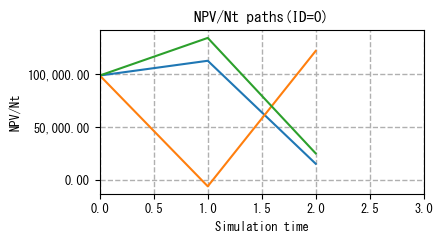

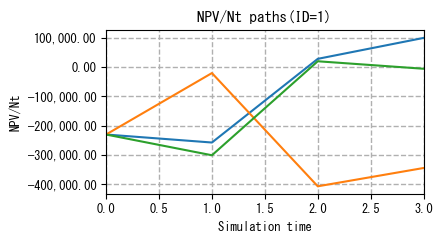

dfCB:
     ID  nDate  nSamp  nDpth           val
0    0      0      0      0   98698.38280
1    0      1      0      0  112650.35900
2    0      1      1      0   -6088.29736
3    0      1      2      0  134273.98400
4    0      2      0      0   15254.05370
5    0      2      1      0  121967.22700
6    0      2      2      0   25061.90230
7    1      0      0      0 -230413.26600
8    1      1      0      0 -257715.70300
9    1      1      1      0  -20887.82620
10   1      1      2      0 -301141.93800
11   1      2      0      0   27613.96290
12   1      2      1      0 -406988.15600
13   1      2      2      0   19335.14260
14   1      3      0      0   99002.80470
15   1      3      1      0 -344532.96900
16   1      3      2      0   -6183.62305


In [8]:
# (数値の確認用) cube gzip読み込みとグラフ
dfCB = pd.read_csv('Output/cube.csv.gz',comment='#',header=None)
dfCB.columns = ['ID','nDate','nSamp','nDpth','val']; nDTmax = dfCB.nDate.max()
# NPV/Nt path plot
for tID in dfCB.ID.unique():                               #  trade IDごとに描画
	val0  = dfCB[(dfCB.ID==tID)&(dfCB.nDate==0)].val.iloc[0]
	dfCB1 = dfCB[(dfCB.ID==tID)&(dfCB.nDate!=0)];   _, ax = plt.subplots()
	for ss in dfCB1.nSamp.unique()[:10]:
		dfPT = dfCB1[dfCB1.nSamp == ss]
		ax.plot(np.r_[0, dfPT.nDate], np.r_[val0, dfPT.val])
	ax.set(xlabel='Simulation time',ylabel='NPV/Nt',xlim=(0,nDTmax))
	ax.set_title(f'NPV/Nt paths(ID={tID})')      ;	yFlt(ax); gdShow(ax)
print('dfCB:\n',dfCB)

**dfEPの内容について**  
* Date列は図4.17のsiDTと同じ
* Time列はActualActual(ISDA)で算出されているため、図4.17 のsiYRとは値が異なる

In [9]:
expOBJ = mainOBJ.getReport("exposure_trade_OIS-1y")
dfEP   = ou.rOBJxdf(expOBJ); print('行,列:',dfEP.shape); display(dfEP.T)

行,列: (4, 12)


,0,1,2,3
TradeId,OIS-1y,OIS-1y,OIS-1y,OIS-1y
Date,2022-08-19,2023-02-20,2023-08-21,2024-02-19
Time,0.0,0.506849,1.005479,1.503743
EPE,98698.382812,82308.117188,54094.394531,0.0
ENE,0.0,2029.432495,0.0,0.0
AllocatedEPE,0.0,0.0,0.0,0.0
AllocatedENE,0.0,0.0,0.0,0.0
PFE,98698.382812,134273.984375,121967.226562,0.0
BaselEE,98698.382812,82303.680829,54100.950564,0.0
BaselEEE,98698.382812,98698.382812,98698.382812,98698.382812


In [10]:
expOBJ = mainOBJ.getReport("exposure_trade_OIS-2y")
dfEP   = ou.rOBJxdf(expOBJ); print('行,列:',dfEP.shape); display(dfEP.T)

行,列: (4, 12)


,0,1,2,3
TradeId,OIS-2y,OIS-2y,OIS-2y,OIS-2y
Date,2022-08-19,2023-02-20,2023-08-21,2024-02-19
Time,0.0,0.506849,1.005479,1.503743
EPE,0.0,0.0,15649.702148,33000.933594
ENE,230413.265625,193248.484375,135662.71875,116905.53125
AllocatedEPE,0.0,0.0,0.0,0.0
AllocatedENE,0.0,0.0,0.0,0.0
PFE,0.0,0.0,27613.962891,99002.804688
BaselEE,0.0,0.0,15651.598601,33016.067337
BaselEEE,0.0,0.0,15651.598601,33016.067337


In [11]:
expOBJ = mainOBJ.getReport("exposure_nettingset_CPTY-An")
dfEP   = ou.rOBJxdf(expOBJ); print('行,列:',dfEP.shape); display(dfEP.T)

行,列: (4, 11)


,0,1,2,3
NettingSet,CPTY-An,CPTY-An,CPTY-An,CPTY-An
Date,2022-08-19,2023-02-20,2023-08-21,2024-02-19
Time,0.0,0.506849,1.005479,1.503743
EPE,0.0,0.0,29088.353516,33000.933594
ENE,131714.875,112969.804688,95006.976562,116905.53125
PFE,0.0,0.0,44397.044922,99002.804688
ExpectedCollateral,-131714.882812,0.0,0.0,0.0
BaselEE,0.0,0.0,29091.879413,33016.067337
BaselEEE,0.0,0.0,29091.879413,33016.067337
TimeWeightedBaselEPE,0.0,0.0,14427.035567,20586.488596


- 列名を変数で指定する場合, []を使う (ドット演算はエラー)

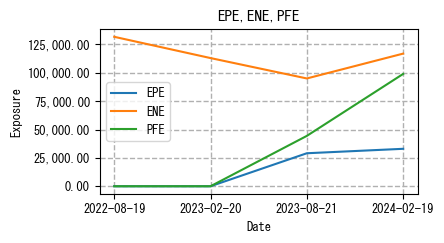

In [12]:
_,ax = plt.subplots()
clLST = ['EPE','ENE','PFE']                          # EPEとPFEが重なる
for ss in clLST: ax.plot(dfEP.Date, dfEP[ss], label=ss)
ax.set(xlabel='Date', ylabel='Exposure') ; ax.set_title('EPE,ENE,PFE')
yFlt(ax); lgD(ax); gdShow(ax)

In [13]:
xvaOBJ = mainOBJ.getReport("xva")
dfXV  = ou.rOBJxdf(xvaOBJ); print('行,列:',dfXV.shape); display(dfXV.T)

行,列: (3, 22)


,0,1,2
TradeId,,OIS-1y,OIS-2y
NettingSetId,CPTY-An,CPTY-An,CPTY-An
CVA,199.193598,444.484296,155.965708
DVA,0.0,0.0,0.0
FBA,0.0,0.0,0.0
FCA,0.0,0.0,0.0
FBAexOwnSP,0.0,0.0,0.0
FCAexOwnSP,0.0,0.0,0.0
FBAexAllSP,0.0,0.0,0.0
FCAexAllSP,0.0,0.0,0.0


In [14]:
necOBJ = mainOBJ.getReport("netcube")
dfNC  = ou.rOBJxdf(necOBJ); print('行,列:',dfNC.shape); display(dfNC)

行,列: (10, 7)


,Id,NettingSet,DateIndex,Date,Sample,Depth,Value
0,CPTY-An,,0,2022-08-19,0,0,-131714.875000
1,CPTY-An,,1,2023-02-20,1,0,-145065.343750
2,CPTY-An,,1,2023-02-20,2,0,-26976.123047
3,CPTY-An,,1,2023-02-20,3,0,-166867.953125
4,CPTY-An,,2,2023-08-21,1,0,42868.015625
5,CPTY-An,,2,2023-08-21,2,0,-285020.937500
6,CPTY-An,,2,2023-08-21,3,0,44397.046875
7,CPTY-An,,3,2024-02-19,1,0,99002.804688
8,CPTY-An,,3,2024-02-19,2,0,-344532.968750
9,CPTY-An,,3,2024-02-19,3,0,-6183.623047


In [15]:
necOBJ = mainOBJ.getReport("rawcube")
dfNC  = ou.rOBJxdf(necOBJ); print('行,列:',dfNC.shape); display(dfNC)

行,列: (20, 7)


,Id,NettingSet,DateIndex,Date,Sample,Depth,Value
0,OIS-1y,CPTY-An,0,2022-08-19,0,0,98698.382812
1,OIS-2y,CPTY-An,0,2022-08-19,0,0,-230413.265625
2,OIS-1y,CPTY-An,1,2023-02-20,1,0,112650.359375
3,OIS-1y,CPTY-An,1,2023-02-20,2,0,-6088.297363
4,OIS-1y,CPTY-An,1,2023-02-20,3,0,134273.984375
5,OIS-1y,CPTY-An,2,2023-08-21,1,0,15254.053711
6,OIS-1y,CPTY-An,2,2023-08-21,2,0,121967.226562
7,OIS-1y,CPTY-An,2,2023-08-21,3,0,25061.902344
8,OIS-1y,CPTY-An,3,2024-02-19,1,0,0.000000
9,OIS-1y,CPTY-An,3,2024-02-19,2,0,0.000000
